In [254]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [255]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines, get_minmax
from crafts_stack.halo_fitting import build_model, halofit

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

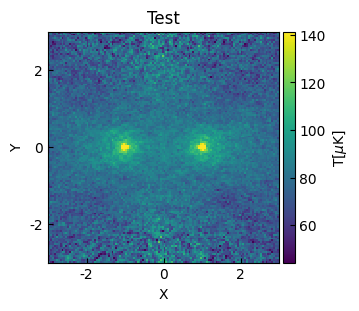

In [256]:
coord = get_coord()

# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']
plot_heatmap(data, title='Test', q=0.1)

In [257]:
# vmax = get_minmax(data, q=0.1)[1]
vmax = 200

data[data > vmax] = vmax

In [276]:
name = 'nfw'
bg_name = 'poly'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'ellipticity_0': (0, 0.5),
    'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    # "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}


model = build_model(name, bg_name, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Polynomial2D(1, c0_0=0., c1_0=0., c0_1=0., x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=0., c1_0=0., c0_1=0., x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... c0_1_2 c0_0_3 c1_0_3 c0_1_3
    ----------- -------- -------- ----- ... ------ ------ ------ ------
           50.0     -1.0      0.0   0.5 ...    0.0    0.0    0.0    0.0


# without mask

In [277]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.026966, x_mean=-1.01042426, y_mean=-0.00010556, r_s=268.65397313, ellipticity=0.33043182, theta=0.02105422)>

    [1]: <NFW2D(amplitude=0.026966, x_mean=1.01092269, y_mean=-0.00008595, r_s=290.43751499, ellipticity=0.39123372, theta=0.02837566)>

    [2]: <Polynomial2D(1, c0_0=34.09929053, c1_0=5.47669229, c0_1=-0.14553319, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=34.09929053, c1_0=-5.88973, c0_1=-0.14556695, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
        amplitude_0            x_mean_0      ...        c0_1_3       
    -------------------- ------------------- ... --------------------
    0.026966002430677555 -1.0104242605238412 ... -0.14556695431677188

Goodness of fit:
Chi-squared: 1016105.073
RMS residual: 8.400


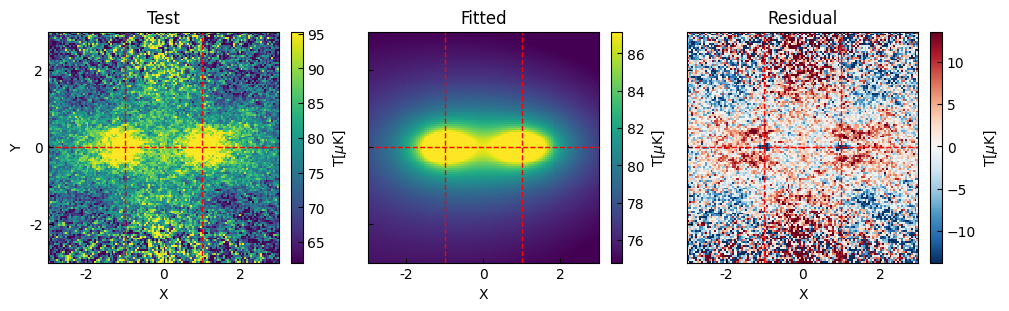

In [278]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

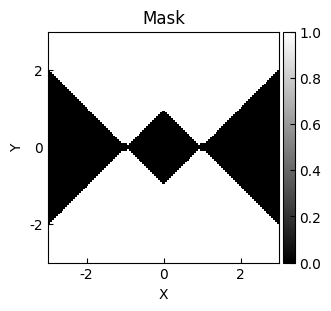

In [285]:
# mask = get_mask_sector(coord=coord)
mask = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [286]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.22681337, x_mean=-1.01514663, y_mean=-0.00236313, r_s=36.17885787, ellipticity=0.36240321, theta=-7.86422582)>

    [1]: <NFW2D(amplitude=0.22681337, x_mean=1.07331138, y_mean=0.00152757, r_s=35.37761002, ellipticity=0.00002956, theta=-0.46123865)>

    [2]: <Polynomial2D(1, c0_0=33.37670252, c1_0=5.34724511, c0_1=-0.1402353, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=33.37670252, c1_0=-5.77853008, c0_1=-0.15411703, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
       amplitude_0           x_mean_0      ...        c0_1_3       
    ------------------ ------------------- ... --------------------
    0.2268133709802912 -1.0151466319169424 ... -0.15411702792052567

Goodness of fit:
Chi-squared: 1161491.493
RMS residual: 8.981


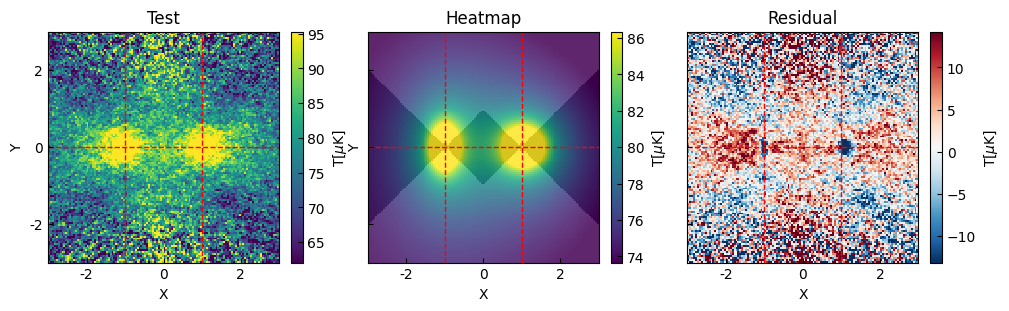

In [287]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

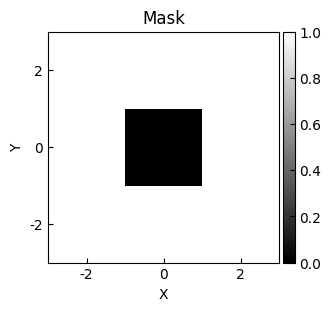

In [288]:
mask = ~get_mask_square(coord=coord)
# mask = ~get_mask_square(coord=coord, xlim=[-0.8, 0.8], ylim=[-0.8, 0.8])
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [289]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=0.12279654, x_mean=-0.94775445, y_mean=0.00295815, r_s=81.9781829, ellipticity=0.18391399, theta=22.12776143)>

    [1]: <NFW2D(amplitude=0.12279654, x_mean=0.93013854, y_mean=-0.00229553, r_s=96.56615223, ellipticity=0.30089015, theta=-15.67537074)>

    [2]: <Polynomial2D(1, c0_0=32.72022372, c1_0=5.153232, c0_1=8.92677202, x_domain=(-4, 2), y_domain=(-3, 3))>

    [3]: <Polynomial2D(1, c0_0=32.72022372, c1_0=-5.57519174, c0_1=-9.22321188, x_domain=(-2, 4), y_domain=(-3, 3))>
Parameters:
        amplitude_0           x_mean_0      ...       c0_1_3      
    ------------------- ------------------- ... ------------------
    0.12279653805457295 -0.9477544529510125 ... -9.223211875822372

Goodness of fit:
Chi-squared: 1431803.959
RMS residual: 9.972


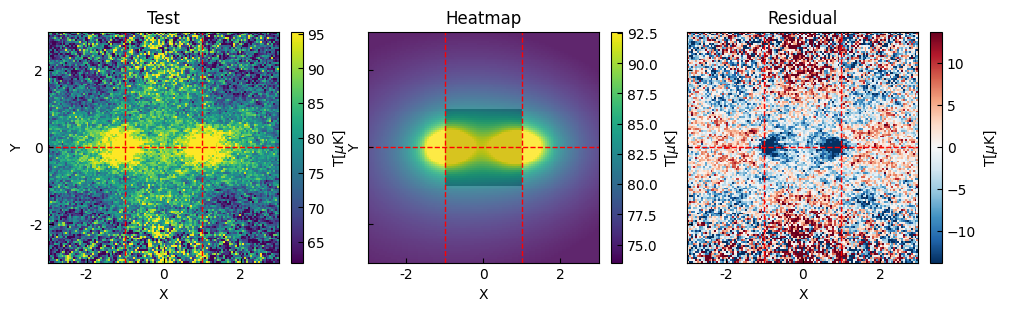

In [290]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [267]:
from mytools.plot import plot_hist

(-100.0, 100.0)

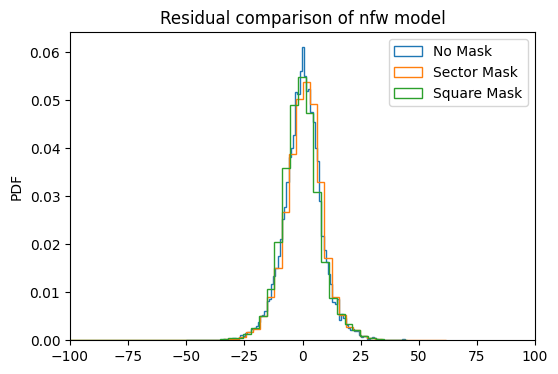

In [268]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [269]:
from mytools.plot import plot_line,plt

In [296]:
stack_fit_res = data_list_sector
# stack_fit_res = data_list_square
# stack_fit_res = data_list

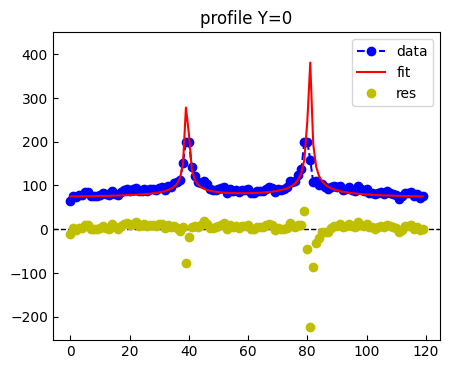

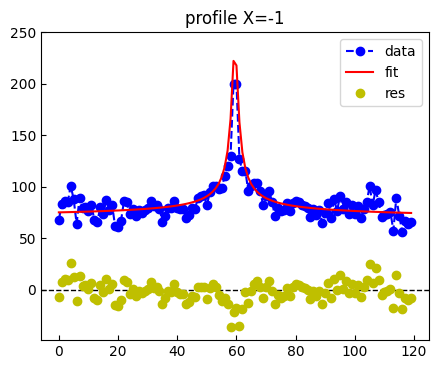

In [297]:
xx = [range(120)]*3

ind = 60
yy = [d[ind] for d in stack_fit_res]
ax= plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plot_axlines(ax=ax, hl=[0], color='k')
plt.title('profile Y=0')
plt.ylim(ymax=450)
plt.legend()

ind = 40
yy = [d[:, ind] for d in stack_fit_res]
ax= plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plot_axlines(ax=ax, hl=[0], color='k')
plt.title('profile X=-1')
plt.ylim(ymax=250)
plt.legend()

# estimate signal level

In [298]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Gauss fit parameters a, sgima, c (and mu): [1.49777442 0.1        4.54767712]
Gauss fit covariance of a, sgima, c (and mu): [[ 3.70792043 -0.15804861 -0.05554422]
 [-0.15804861  0.02250509 -0.0074169 ]
 [-0.05554422 -0.0074169   0.07855139]]
width: 0.10000000000360952
width_pix: 2


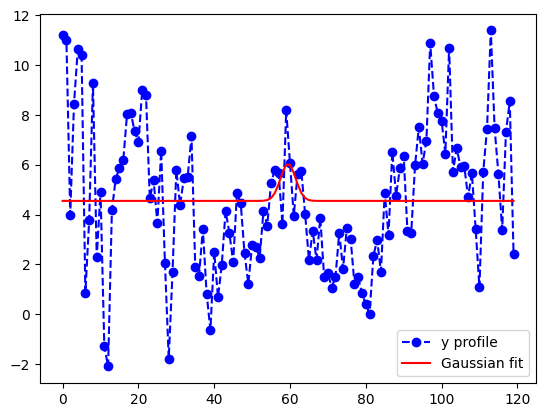

In [304]:
res = stack_fit_res[-1]
bounds = (
    [0, 0.1, -np.inf],
    [np.inf, 0.7, np.inf],
)
lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

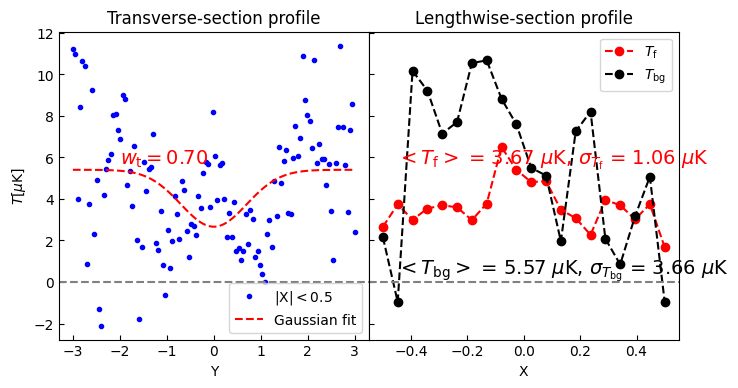

In [300]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[1], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

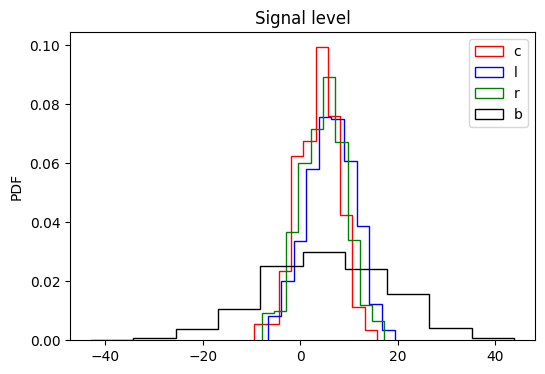

In [301]:
plot_hist(clrb, label=['c','l','r','b'], color=['r', 'b','g','k'], title='Signal level')